# Resonance Overlap: When Do Two Close Planets Become Chaotic?

*Matthew Payne*

The *Kepler* mission found many systems of planets on nearly circular, nearly coplanar orbits, packed so closely that neighbouring period ratios lie between 1 and 2. How close can two planets be and still remain stable for billions of years?

This notebook reproduces, with direct numerical experiments, the main results of

> K. M. Deck, M. Payne & M. J. Holman (2013), *First-order Resonance Overlap and the Stability of Close Two-planet Systems*, ApJ **774**, 129. [ADS](https://ui.adsabs.harvard.edu/abs/2013ApJ...774..129D/abstract) · [arXiv:1307.8119](https://arxiv.org/abs/1307.8119)

We will:

1. See why first-order mean motion resonances must overlap when two planets are close enough.
2. Draw the separatrices of those resonances from the paper's reduced Hamiltonian, and find where neighbours first touch.
3. Map the Lyapunov time over half a million two-planet integrations: against period ratio and eccentricity, against the initial orbital phase, and across planet masses.
4. Compare the edge of chaos with the overlap criterion and the Hill stability boundary.
5. Show that an orbit can be Hill stable and still be unstable: its period ratio wanders erratically through the chaotic web.

Figure numbers refer to the arXiv version of the paper.

**Requirements:** `numpy`, `matplotlib` and `rebound` (version 4 or later).

**Run time:** the full-resolution maps are about half a million integrations, roughly 2 hours on a 12-core laptop. Their results are cached in `cache/`, so the notebook normally re-runs in seconds. Set `RECOMPUTE = True` to redo them, or `QUICK = True` for coarse maps that take a few minutes.

In [1]:
import os
import time
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

import overlap as ov   # helper module in this folder: criteria, separatrices and integrations

QUICK = False          # True: coarse grids, a few minutes from scratch
RECOMPUTE = False      # True: ignore cached results and integrate again
NPROC = os.cpu_count()
CACHE = "cache_quick" if QUICK else "cache"
print(f"Using {NPROC} processes; QUICK = {QUICK}; RECOMPUTE = {RECOMPUTE}")

# Colour scale for log10(T_Ly / P1), in the style of DPH13's figures:
# short Lyapunov times (strongly chaotic) dark, long times (regular) yellow.
LY_CMAP = LinearSegmentedColormap.from_list("lyapunov", [
    "#03030f", "#0b1f55", "#2f6f80", "#4f9a6a", "#3a7f2e", "#7a2a12",
    "#c4160c", "#d9662a", "#eaa53a", "#f7ec4a"])
LY_MIN, LY_MAX = 0.5, 2.76    # the range used in DPH13
T_DAYS = 1e6                  # DPH13's standard run: 1e6 days with the outer period set to one year

def ly_image(ax, x, y, values, **kw):
    # -inf (scattered) and +inf (no tangent growth) clip to the ends of the scale
    return ax.pcolormesh(x, y, np.clip(values, LY_MIN, LY_MAX), cmap=LY_CMAP,
                         vmin=LY_MIN, vmax=LY_MAX, shading="nearest", rasterized=True, **kw)

def grid_jobs(rows, cols, make):
    return [make(r, c) for r in rows for c in cols]

Using 12 processes; QUICK = False; RECOMPUTE = False


## Two Classic Answers

Write $\epsilon_p = (m_1+m_2)/M_\star$ for the total planetary mass relative to the star, and $\Delta = (a_2-a_1)/a_1$ for the fractional separation of the orbits.

**Hill stability.** Conservation of energy and angular momentum can forbid the two orbits from ever crossing ([Marchal & Bozis 1982](https://ui.adsabs.harvard.edu/abs/1982CeMec..26..311M/abstract); [Gladman 1993](https://ui.adsabs.harvard.edu/abs/1993Icar..106..247G/abstract)). For initially circular orbits this holds when

$$\Delta \gtrsim 2.4\,\epsilon_p^{1/3}.$$

A Hill-stable pair can never have a close encounter. But the criterion says nothing about whether the orbits themselves stay put.

**Resonance overlap.** When two independent resonances overlap, motion between them becomes chaotic ([Chirikov 1979](https://ui.adsabs.harvard.edu/abs/1979PhR....52..263C/abstract)). [Wisdom (1980)](https://ui.adsabs.harvard.edu/abs/1980AJ.....85.1122W/abstract) applied this to a test particle near a planet and found chaos for $\Delta \lesssim 1.3\,\epsilon^{2/7}$. Deck, Payne & Holman (2013) extended the calculation to **two massive planets**, by reducing the Hamiltonian near a first-order resonance to one degree of freedom. For initially circular orbits they find overlap, and widespread chaos, when

$$\Delta \lesssim 1.46\,\epsilon_p^{2/7}, \qquad\text{equivalently}\qquad \frac{P_2}{P_1} \lesssim 1 + 2.2\,\epsilon_p^{2/7}.$$

At lowest order the planetary mass ratio $m_1/m_2$ drops out, so only the total mass matters.

## 1. Why Overlap Is Inevitable

The first-order resonances sit at period ratios $P_2/P_1 = (m+1)/m$: 2:1, 3:2, 4:3, and so on. Two things happen as $m$ grows and the resonances crowd towards $P_2/P_1 = 1$:

* **They get closer together.** In $\alpha = a_1/a_2$, neighbouring resonances are separated by $\Delta\alpha/\alpha \approx 2/(3m^2)$.
* **They get wider.** For circular orbits, DPH13 find each resonance has a full width $\delta\alpha/\alpha \approx 4.18\,\epsilon_p^{2/3} m^{1/3}$.

Spacing falls as $m^{-2}$ while width grows as $m^{1/3}$, so beyond some $m$ every resonance touches its neighbour. Setting spacing equal to width gives $m \approx 0.455\,\epsilon_p^{-2/7}$, which is where the criterion above comes from.

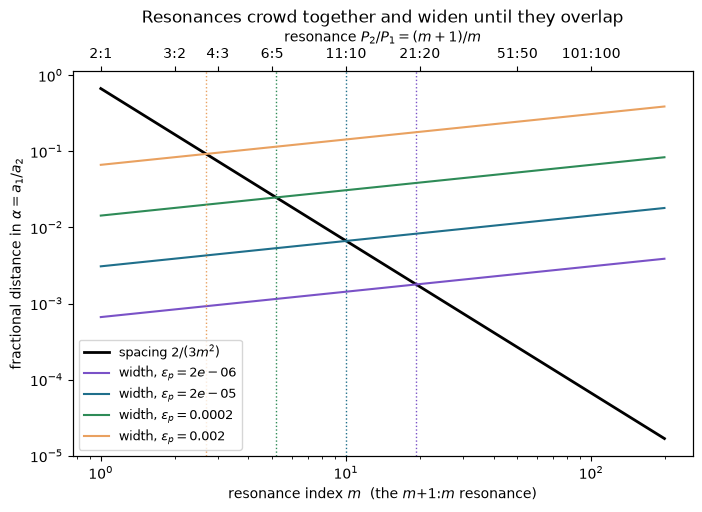

eps_p = 2e-06:  overlap beyond m ≈  19.3,  i.e. P2/P1 < 1.052
eps_p = 2e-05:  overlap beyond m ≈  10.0,  i.e. P2/P1 < 1.100
eps_p = 0.0002:  overlap beyond m ≈   5.2,  i.e. P2/P1 < 1.193
eps_p = 0.002:  overlap beyond m ≈   2.7,  i.e. P2/P1 < 1.373


In [2]:
m = np.arange(1, 200)
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(m, ov.resonance_spacing(m), color="black", lw=2, label=r"spacing $2/(3m^2)$")
for eps, col in [(2e-6, "#7a52c7"), (2e-5, "#1f6f8b"), (2e-4, "#2e8b57"), (2e-3, "#e9a160")]:
    ax.loglog(m, ov.resonance_full_width(eps, m), color=col, label=rf"width, $\epsilon_p = {eps:g}$")
    ax.axvline(0.455 * eps ** (-2 / 7), color=col, ls=":", lw=1)
ax.set_xlabel("resonance index $m$  (the $m{+}1$:$m$ resonance)")
ax.set_ylabel(r"fractional distance in $\alpha = a_1/a_2$")
ax.set_title("Resonances crowd together and widen until they overlap")
ax.legend(fontsize=9)
top = ax.twiny()
top.set_xscale("log"); top.set_xlim(ax.get_xlim())
ticks = [1, 2, 3, 5, 10, 20, 50, 100]
top.set_xticks(ticks, [f"{t + 1}:{t}" for t in ticks]); top.minorticks_off()
top.set_xlabel("resonance $P_2/P_1 = (m+1)/m$")
plt.show()

for eps in [2e-6, 2e-5, 2e-4, 2e-3]:
    print(f"eps_p = {eps:g}:  overlap beyond m ≈ {0.455 * eps ** (-2 / 7):5.1f},  "
          f"i.e. P2/P1 < {ov.overlap_period_ratio_circular(eps):.3f}")

For two Jupiter-mass planets ($\epsilon_p \approx 2\times10^{-3}$) overlap begins near the 4:3 resonance. For two Earths around a Sun-like star ($\epsilon_p \approx 6\times10^{-6}$), resonances do not overlap until about $P_2/P_1 \approx 1.07$.

This is a lowest-order estimate: it ignores second- and higher-order resonances, whose own chaotic layers join neighbouring first-order resonances before they touch. The criterion is therefore a *minimum* extent for chaos.

## 2. The Separatrices

Near the $m{+}1$:$m$ resonance, DPH13 reduce the two-planet Hamiltonian, through a sequence of canonical transformations, to

$$H' = -\tfrac{1}{2}\left[\tfrac{1}{2}(X^2+Y^2) - \Gamma'\right]^2 - X,$$

with a single parameter $\Gamma'$, which combines the period ratio and the *weighted eccentricity*

$$\sigma = \sqrt{e_1^2 + e_2^2/R^2 - (2/R)\,e_1 e_2 \cos\Delta\varpi}, \qquad R = |f_{27}/f_{31}| \approx 1.$$

For $\Gamma' > 3/2$ there is a separatrix through the saddle point $X_3$ (the largest root of $X^3 - 2\Gamma' X + 2 = 0$), crossing the $X$ axis at $X = -X_3 \pm 2/\sqrt{X_3}$. Mapping those crossings back to period ratio and $\sigma$ (with the paper's fits $f_{27} \approx -0.46 - 0.802m$ and $f_{31} \approx 0.87 + 0.802m$) gives the boundary of each resonance; this is `ov.resonance_separatrix`.

The separatrices widen with $\sigma$. Where the outer boundary of one resonance meets the inner boundary of its neighbour (red dots), the two overlap. DPH13 approximate the locus of these points by $P_2/P_1 \approx 1 + 2.08\,(\epsilon_p\sigma)^{1/5}$ at higher $\sigma$, joining the circular-orbit criterion below $\sigma \approx 1.33\,\epsilon_p^{3/7}$. This is the paper's Figure 4.

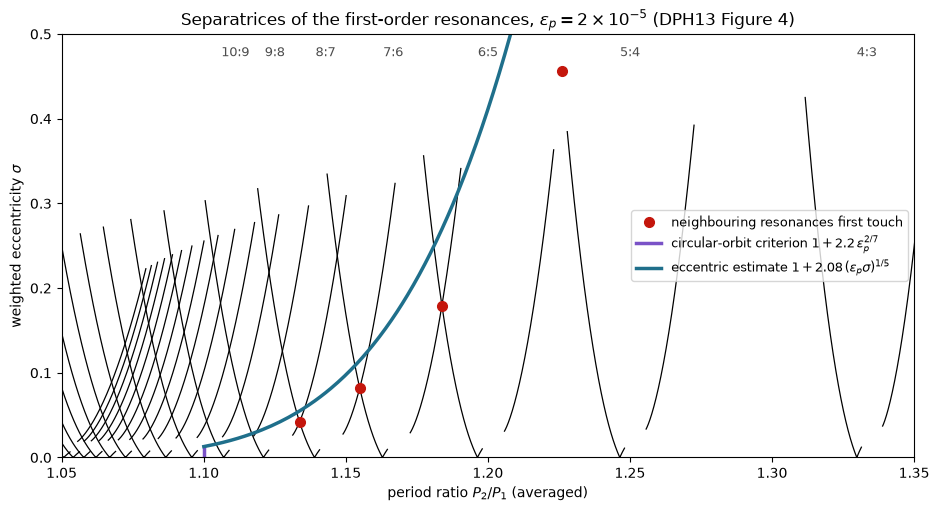

6:5 meets 5:4 at P2/P1 = 1.2260, sigma = 0.456
7:6 meets 6:5 at P2/P1 = 1.1838, sigma = 0.179
8:7 meets 7:6 at P2/P1 = 1.1549, sigma = 0.082
9:8 meets 8:7 at P2/P1 = 1.1337, sigma = 0.042


In [3]:
EPS = 2e-5
fig, ax = plt.subplots(figsize=(11, 5.5))
for mm in range(3, 22):
    for pr_c, s_c in ov.resonance_separatrix(EPS, mm, n=800, gamma_max=600):
        ax.plot(pr_c, s_c, color="black", lw=0.9)
    p_nom = (mm + 1) / mm
    if mm <= 9:
        ax.text(p_nom, 0.485, f"{mm + 1}:{mm}", ha="center", va="top", fontsize=9, color="0.3")
cross = ov.separatrix_crossings(EPS, range(3, 21))
ax.plot([c[0] for c in cross], [c[1] for c in cross], "o", color="#c4160c", ms=7, zorder=5,
        label="neighbouring resonances first touch")
sig_switch = 1.33 * EPS ** (3 / 7)
ax.plot([ov.overlap_period_ratio_circular(EPS)] * 2, [0, sig_switch], color="#7a52c7", lw=2.5,
        label=r"circular-orbit criterion $1 + 2.2\,\epsilon_p^{2/7}$")
sig = np.linspace(sig_switch, 0.5, 200)
ax.plot(ov.overlap_period_ratio_eccentric(EPS, sig), sig, color="#1f6f8b", lw=2.5,
        label=r"eccentric estimate $1 + 2.08\,(\epsilon_p\sigma)^{1/5}$")
ax.set_xlim(1.05, 1.35); ax.set_ylim(0, 0.5)
ax.set_xlabel("period ratio $P_2/P_1$ (averaged)")
ax.set_ylabel(r"weighted eccentricity $\sigma$")
ax.set_title(rf"Separatrices of the first-order resonances, $\epsilon_p = 2\times10^{{-5}}$ (DPH13 Figure 4)")
ax.legend(loc="center right", fontsize=9)
plt.show()
for pr_c, s_c, mm in cross:
    print(f"{mm + 2}:{mm + 1} meets {mm + 1}:{mm} at P2/P1 = {pr_c:.4f}, sigma = {s_c:.3f}")

Below $\sigma \approx 0.01$ the resonances closer to unity than about 10:9 already overlap at zero eccentricity; that is the circular-orbit criterion, $P_2/P_1 < 1.10$. Each resonance's inner boundary dips to $\sigma = 0$ in a small hook, the bottom of the separatrix. As $\sigma$ grows, the resonances spread and overlap at ever larger period ratios. Note that the theory assumes small eccentricities; the curves above $\sigma \sim 0.1$ test the criterion's form rather than describe real orbits.

## 3. Mapping Chaos: Period Ratio, Eccentricity and Phase

Now the numerical test. We integrate two equal-mass planets with $\epsilon_p = 2\times10^{-5}$ (about 3.3 Earth masses each around a Sun-like star) over a fine grid of initial period ratios and inner eccentricities. The outer orbit starts circular, so $\sigma = e_1$. All angles start at zero except the inner planet's mean anomaly $M_1$, and we repeat the map for $M_1 = 0$, $\pi/10$ and $\pi/2$, as in the paper's Figure 5.

Each run follows DPH13's recipe:
* The outer period is one year, and the run lasts $10^6$ days (about 2,700 outer orbits).
* A Wisdom–Holman integrator (REBOUND's WHFast, 50 steps per inner orbit) carries a random tangent vector along with the orbit.
* The Lyapunov time is estimated as $T_\mathrm{Ly} = t_\mathrm{final}/\ln d$, where $d$ is the tangent vector's final length.

Regular orbits give $T_\mathrm{Ly}$ of order a tenth to a hundredth of the run (yellow). Chaotic orbits give much shorter times (red, green, then blue to black). Runs where the planets scatter are certainly chaotic and plot black.

DPH13 also used a symplectic corrector. REBOUND cannot combine one efficiently with its variational equations, and a corrector improves energy errors rather than which orbits are chaotic, so we do without.

Overlaid in grey are the analytic separatrices from Section 2. The dotted white curve is the Hill boundary, computed exactly for each starting configuration with Gladman's criterion; to its left the planets may have close encounters.

In [4]:
EPS = 2e-5
n_pr, n_sig = (150, 40) if QUICK else (600, 150)
prs = np.linspace(1.05, 1.35, n_pr)
sigs = np.linspace(0.0, 0.10, n_sig)
M1S = [(0.0, r"$M_1 = 0$"), (np.pi / 10, r"$M_1 = \pi/10$"), (np.pi / 2, r"$M_1 = \pi/2$")]

maps = []
t0 = time.time()
for k, (M1, _) in enumerate(M1S):
    jobs = grid_jobs(sigs, prs, lambda s, p: (EPS, p, s, M1, T_DAYS))
    vals = ov.cached_grid(f"{CACHE}/fig5_M1_{k}.npz", jobs, ov.lyapunov_time, NPROC, RECOMPUTE)
    maps.append(vals.reshape(n_sig, n_pr))
print(f"{3 * n_pr * n_sig} integrations ready in {time.time() - t0:.0f} s")

hill_sig = np.linspace(0, 0.10, 21)
hill_curves = [[ov.hill_period_ratio(EPS, e1=s, M1=M1) for s in hill_sig] for M1, _ in M1S]

270000 integrations ready in 0 s


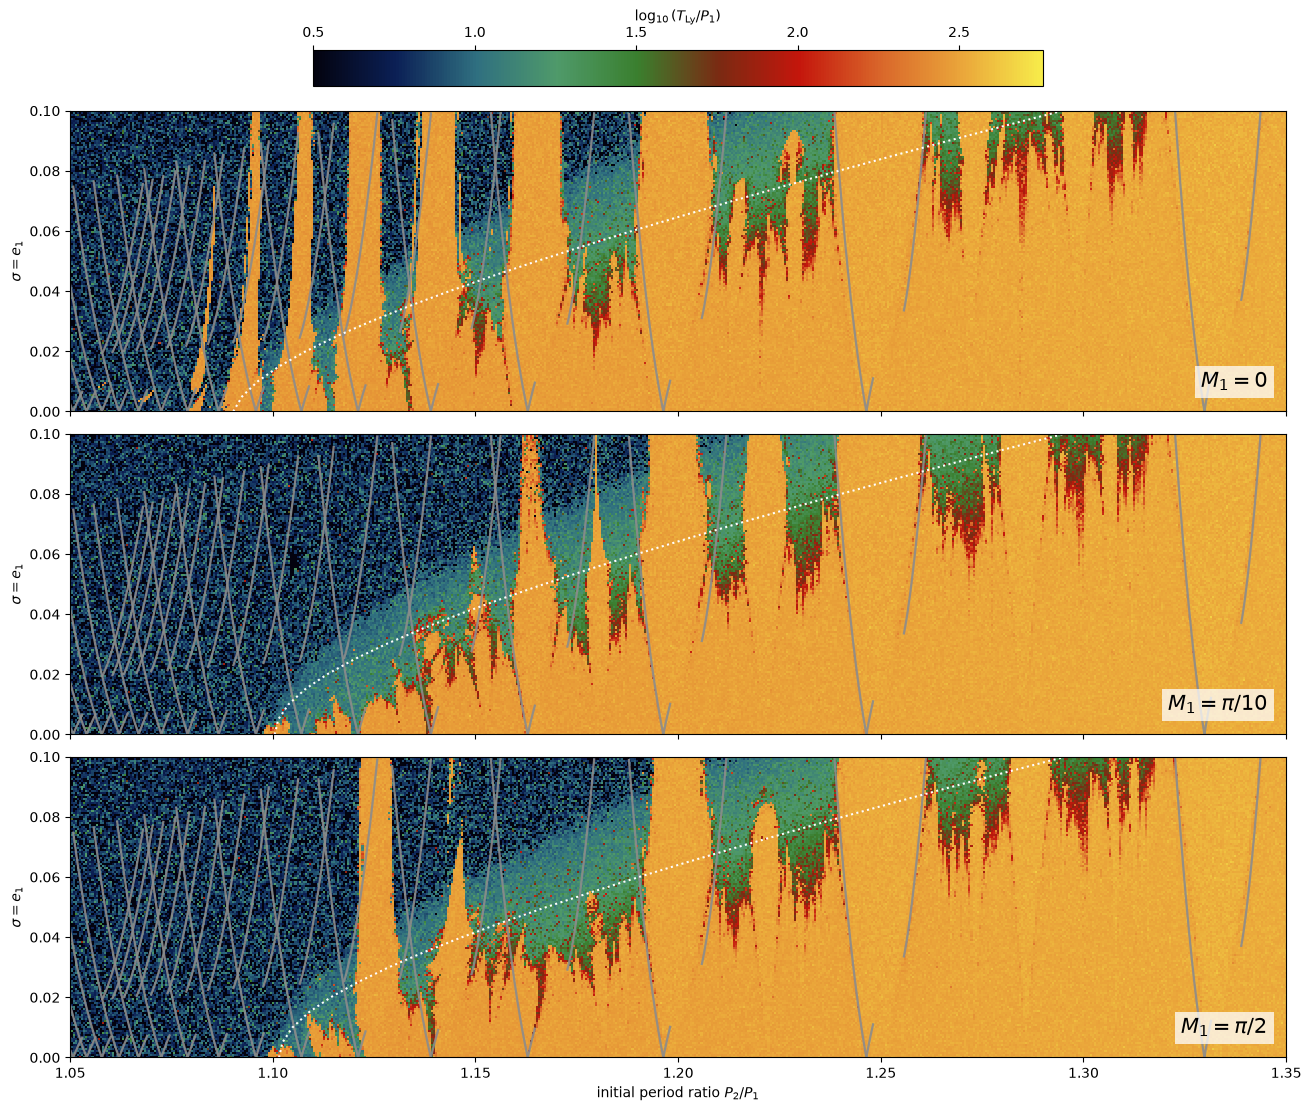

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True, constrained_layout=True)
for ax, T, (M1, label), hill in zip(axes, maps, M1S, hill_curves):
    im = ly_image(ax, prs, sigs, T)
    for mm in range(3, 21):
        for pr_c, s_c in ov.resonance_separatrix(EPS, mm):
            ok = s_c <= 0.1
            ax.plot(pr_c[ok], s_c[ok], color="0.55", lw=1.6, alpha=0.9)
    ax.plot(hill, hill_sig, color="white", lw=1.5, ls=":")
    ax.set_xlim(prs[0], prs[-1]); ax.set_ylim(0, 0.10)
    ax.set_ylabel(r"$\sigma = e_1$")
    ax.text(0.985, 0.08, label, transform=ax.transAxes, ha="right", fontsize=15,
            bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"))
axes[-1].set_xlabel("initial period ratio $P_2/P_1$")
cb = fig.colorbar(im, ax=axes, location="top", shrink=0.6, pad=0.02)
cb.set_label(r"$\log_{10}(T_\mathrm{Ly}/P_1)$")
plt.show()

What the maps show, and how they match the paper's Figure 5:

* **Complete overlap near unity.** Below $P_2/P_1 \approx 1.1$, where the separatrices pile up, essentially every orbit is strongly chaotic, whatever the phase.
* **A chaotic web beyond it.** Further out, chaos follows the separatrices of individual resonances: each resonance carries a chaotic layer that widens with eccentricity, and neighbouring layers merge where the separatrices cross.
* **Phase matters in detail.** The starting phase changes where complete overlap ends at low eccentricity: near $P_2/P_1 \approx 1.09$ for $M_1 = 0$, along a diagonal for $M_1 = \pi/10$, and near 1.12 for $M_1 = \pi/2$. It also moves the regular islands. The separatrices are drawn in averaged coordinates, which differ slightly from the initial osculating period ratio, by an amount that depends on the phase.
* **The Hill boundary** (dotted) starts near $P_2/P_1 \approx 1.10$ for circular orbits and moves outwards with eccentricity. Chaos extends well beyond it.
* **Red fringes** below each chaotic band are weakly chaotic orbits near the separatrices, with Lyapunov times of about a hundred inner orbits. The paper's Appendix shows that longer runs flag a few more such orbits, mostly near second-order resonances, but leave the overall structure unchanged.

## 4. Mapping Chaos Across Planet Masses

The resonance widths grow as $\epsilon_p^{2/3}$, so the chaotic web should grow with the planets' mass. Following the paper's Figure 9, we fix $e_1 = 0.01$ and $e_2 = 0$, and map the Lyapunov time against the inner planet's initial mean anomaly $M_1$ and the period ratio, for three total masses: $\epsilon_p = 2\times10^{-3}$, $2\times10^{-4}$ and $2\times10^{-5}$ (roughly two Jupiters, two Neptunes and two super-Earths around a Sun-like star).

The white curve is the exact Hill boundary for each starting configuration. It dips at $M_1 = 0$, where the planets start at conjunction.

In [6]:
PANELS = [(2e-3, 1.10, 1.70), (2e-4, 1.15, 1.35), (2e-5, 1.05, 1.20)]
n_m1, n_pr9 = (90, 40) if QUICK else (361, 160)
m1s = np.linspace(-np.pi, np.pi, n_m1)

maps9, hill9 = [], []
t0 = time.time()
for k, (eps, lo, hi) in enumerate(PANELS):
    prs9 = np.linspace(lo, hi, n_pr9)
    jobs = grid_jobs(prs9, m1s, lambda p, M: (eps, p, 0.01, M, T_DAYS))
    vals = ov.cached_grid(f"{CACHE}/fig9_eps_{k}.npz", jobs, ov.lyapunov_time, NPROC, RECOMPUTE)
    maps9.append((prs9, vals.reshape(n_pr9, n_m1)))
    hill9.append([ov.hill_period_ratio(eps, e1=0.01, M1=M) for M in np.linspace(-np.pi, np.pi, 73)])
print(f"{3 * n_m1 * n_pr9} integrations ready in {time.time() - t0:.0f} s")

173280 integrations ready in 0 s


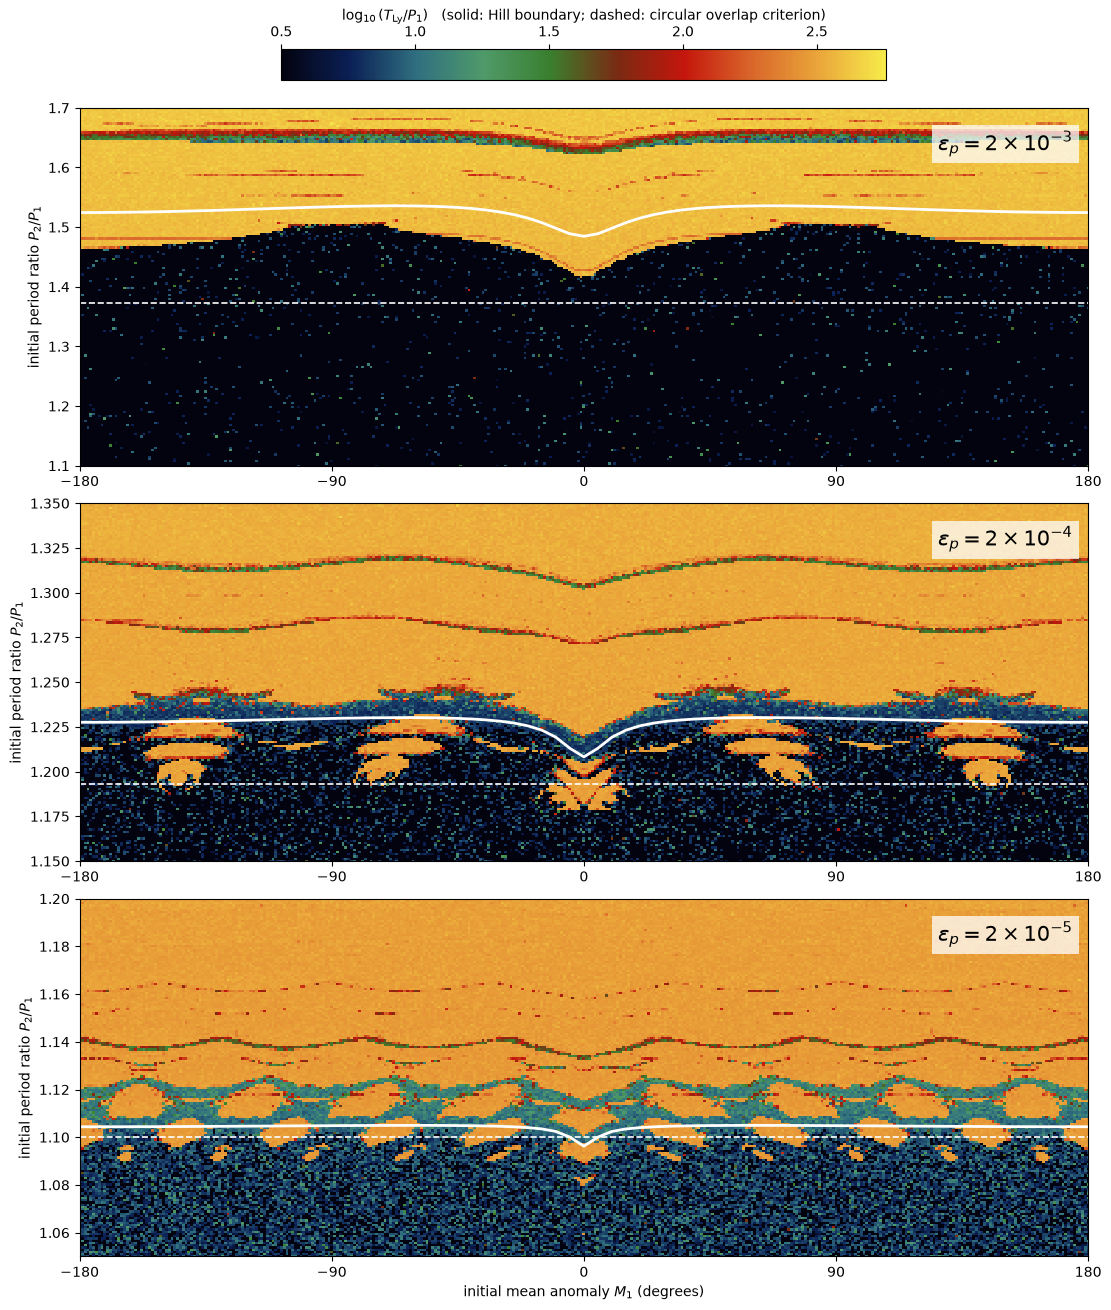

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(11, 13), constrained_layout=True)
for ax, (eps, lo, hi), (prs9, T), hill in zip(axes, PANELS, maps9, hill9):
    im = ly_image(ax, np.degrees(m1s), prs9, T)
    ax.plot(np.linspace(-180, 180, 73), hill, color="white", lw=2)
    ax.axhline(ov.overlap_period_ratio_circular(eps), color="white", lw=1.2, ls="--")
    ax.set_ylim(lo, hi); ax.set_xlim(-180, 180)
    ax.set_ylabel("initial period ratio $P_2/P_1$")
    exponent = int(np.floor(np.log10(eps)))
    ax.text(0.985, 0.88, rf"$\epsilon_p = {eps / 10 ** exponent:.0f}\times10^{{{exponent}}}$", transform=ax.transAxes,
            ha="right", fontsize=15, bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"))
    ax.set_xticks([-180, -90, 0, 90, 180])
axes[-1].set_xlabel(r"initial mean anomaly $M_1$ (degrees)")
cb = fig.colorbar(im, ax=axes, location="top", shrink=0.6, pad=0.02)
cb.set_label(r"$\log_{10}(T_\mathrm{Ly}/P_1)$   (solid: Hill boundary; dashed: circular overlap criterion)")
plt.show()

At the highest mass there are no resonant islands at all: the first-order resonances overlap completely up to $P_2/P_1 \approx 1.45$–1.5 (lowest, about 1.42, for planets starting at conjunction), well beyond the circular overlap criterion (dashed), which underestimates the chaotic zone at high mass. The transition to mostly regular motion there is abrupt. The paper attributes it to the 3:2 resonance overlapping the second-order 7:5 below it but not the 5:3 above; the narrow chaotic band at 1.667 is the 5:3 itself.

At lower masses, resonant islands appear within the chaotic zone, and the chaotic web reaches just beyond the Hill boundary. The narrow chaotic bands at larger period ratios trace individual first- and second-order resonances.

## 5. The Edge of Chaos for Circular Orbits

The overlap criterion predicts that the chaotic zone for initially circular orbits scales as $\epsilon_p^{2/7}$. The Hill boundary scales as $\epsilon_p^{1/3}$. Because the exponents differ, the two lines must cross, at

$$\epsilon_p = (1.46/2.4)^{21} \approx 3\times10^{-5},$$

about ten Earth masses around a Sun-like star. For heavier planets the Hill criterion is the stricter one. For lighter planets the zone of complete overlap reaches *beyond* the Hill boundary, so even some Hill-stable pairs are chaotic.

As in the paper's Figure 10, we map initially circular pairs over $\epsilon_p$ and $\Delta$, for two starting phases.

In [8]:
n_e, n_d = (41, 51) if QUICK else (101, 121)
log_eps = np.linspace(-7, -3, n_e)
log_delta = np.linspace(-2.6, -0.6, n_d)
maps10 = []
t0 = time.time()
for k, M1 in enumerate([0.0, np.pi / 2]):
    jobs = grid_jobs(log_delta, log_eps, lambda ld, le: (10 ** le, (1 + 10 ** ld) ** 1.5, 0.0, M1, T_DAYS))
    vals = ov.cached_grid(f"{CACHE}/fig10_M1_{k}.npz", jobs, ov.lyapunov_time, NPROC, RECOMPUTE)
    maps10.append(vals.reshape(n_d, n_e))
print(f"{2 * n_e * n_d} integrations ready in {time.time() - t0:.0f} s")

24442 integrations ready in 0 s


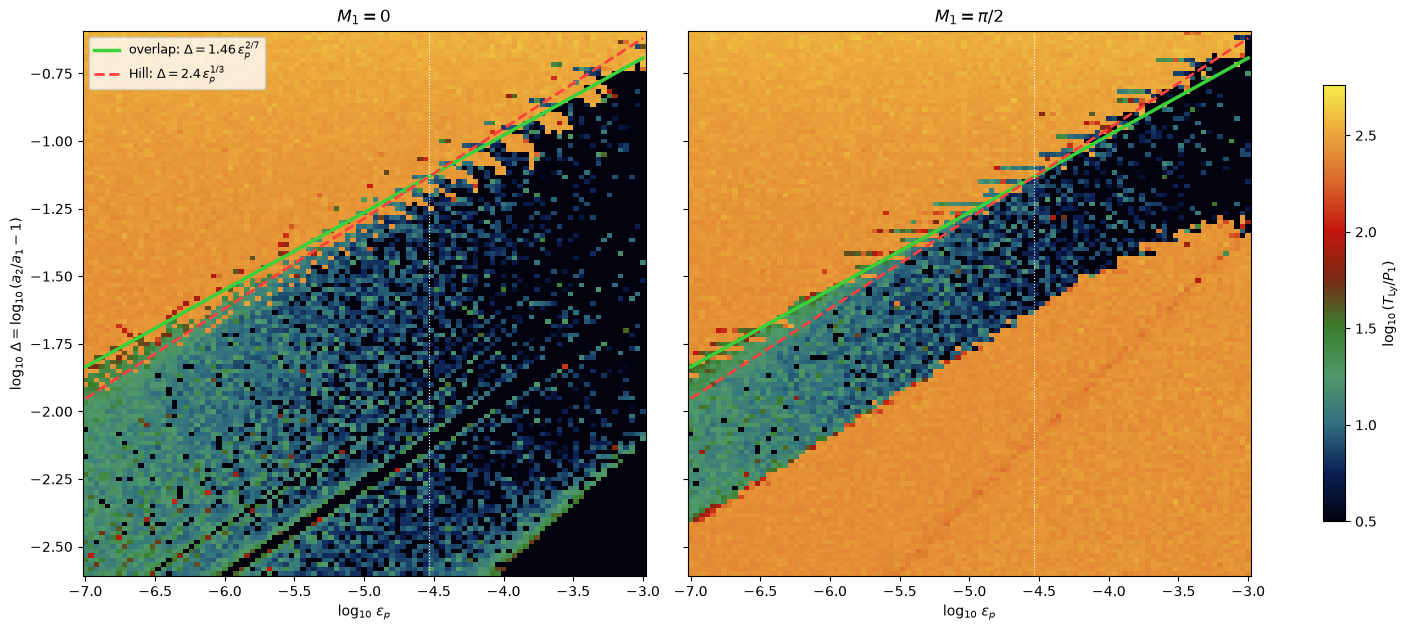

log10(eps)   edge of chaos, log10(Delta), M1 = 0 / pi/2     predicted overlap edge
   -7.00           -1.92 /  -1.83                        -1.84
   -6.60           -1.80 /  -1.75                        -1.72
   -6.20           -1.68 /  -1.60                        -1.61
   -5.80           -1.52 /  -1.50                        -1.49
   -5.40           -1.40 /  -1.30                        -1.38
   -5.00           -1.22 /  -1.23                        -1.26
   -4.60           -1.13 /  -1.10                        -1.15
   -4.20           -1.02 /  -0.98                        -1.04
   -3.80           -0.85 /  -0.82                        -0.92
   -3.40           -0.73 /  -0.70                        -0.81
   -3.00           -0.75 /  -0.62                        -0.69


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True, constrained_layout=True)
e = np.logspace(-7, -3, 100)
for ax, T, label in zip(axes, maps10, [r"$M_1 = 0$", r"$M_1 = \pi/2$"]):
    im = ly_image(ax, log_eps, log_delta, T)
    ax.plot(np.log10(e), np.log10(ov.overlap_delta_circular(e)), color="#3ad13a", lw=2.5,
            label=r"overlap: $\Delta = 1.46\,\epsilon_p^{2/7}$")
    ax.plot(np.log10(e), np.log10(ov.hill_delta_circular(e)), color="#ff4040", lw=2, ls="--",
            label=r"Hill: $\Delta = 2.4\,\epsilon_p^{1/3}$")
    ax.axvline(np.log10((1.46 / 2.4) ** 21), color="white", lw=0.8, ls=":")
    ax.set_xlabel(r"$\log_{10}\,\epsilon_p$")
    ax.set_title(label)
axes[0].set_ylabel(r"$\log_{10}\,\Delta = \log_{10}(a_2/a_1 - 1)$")
axes[0].legend(loc="upper left", fontsize=9)
cb = fig.colorbar(im, ax=axes, shrink=0.8)
cb.set_label(r"$\log_{10}(T_\mathrm{Ly}/P_1)$")
plt.show()

# Where does strong chaos stop? For each mass, the widest separation with log10(T_Ly/P1) < 1.5
print("log10(eps)   edge of chaos, log10(Delta), M1 = 0 / pi/2     predicted overlap edge")
for j in range(0, n_e, max(1, n_e // 10)):
    edges = []
    for T in maps10:
        chaotic = np.where(T[:, j] < 1.5)[0]
        edges.append(log_delta[chaotic].max() if len(chaotic) else np.nan)
    print(f"   {log_eps[j]:5.2f}          {edges[0]:6.2f} / {edges[1]:6.2f}                       "
          f"{np.log10(ov.overlap_delta_circular(10 ** log_eps[j])):6.2f}")

The edge of the strongly chaotic zone follows the $\epsilon_p^{2/7}$ overlap line across four decades in mass. At the highest masses it lies slightly beyond the line, close to the Hill boundary; the paper found the same, and attributes it to terms neglected in the lowest-order theory. The few chaotic points above the line sit on individual resonances, which a criterion for *complete* overlap does not describe.

The large regular region at small separations in the $M_1 = \pi/2$ panel is the 1:1 resonance: the planets start a quarter of an orbit apart on nearly the same orbit, and are protected as co-orbitals, on tadpole or horseshoe orbits. The criterion explicitly excludes this case, and the paper notes the same region. Starting at conjunction ($M_1 = 0$) gives no such protection.

For $\epsilon_p \lesssim 3\times10^{-5}$ the overlap line lies *above* the Hill line. Between the two is a wedge of pairs that are Hill stable, so they can never have a close encounter, yet whose orbits are chaotic.

## 6. Hill Stable, Yet Unstable

What happens to a pair in that wedge? DPH13 showed that orbits in the overlap region are *Lagrange unstable*: their semimajor axes, and so their period ratio, wander erratically through the chaotic web, even when the Hill criterion forbids a close encounter (their Figure 14).

Take $\epsilon_p = 10^{-6}$ (two planets of about 0.17 Earth masses each around a Sun-like star). The Hill boundary is at $\Delta = 0.024$ and the overlap edge at $\Delta = 0.028$. We follow two initially circular pairs for a million inner orbits:

* $\Delta = 0.026$: Hill stable, but **inside** the overlap zone;
* $\Delta = 0.034$: Hill stable and **outside** the overlap zone.

Because both pairs are Hill stable, close encounters cannot occur, so a fixed-step symplectic integrator stays accurate throughout. The final energy error is printed as a check.

Hill boundary Delta = 0.0240,  overlap edge Delta = 0.0282


done in 20 s
Delta = 0.026: period ratio 1.0393 to 1.2446; |dE/E| = 2.8e-11
Delta = 0.034: period ratio 1.0497 to 1.0516; |dE/E| = 1.1e-12


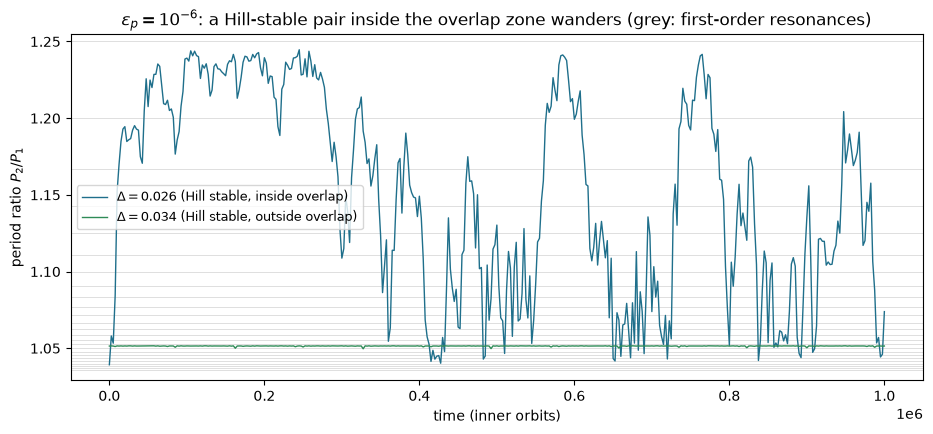

In [10]:
EPS6 = 1e-6
N6 = 2e5 if QUICK else 1e6
print(f"Hill boundary Delta = {ov.hill_delta_circular(EPS6):.4f},  overlap edge Delta = {ov.overlap_delta_circular(EPS6):.4f}")

runs = [(EPS6, 0.026, N6), (EPS6, 0.034, N6)]
t0 = time.time()
with Pool(2) as pool:
    histories = pool.starmap(ov.period_ratio_history, runs)
print(f"done in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(11, 4.5))
for (eps, delta, _), (t, ratio, dE), col in zip(runs, histories, ["#1f6f8b", "#2e8b57"]):
    inside = "inside" if delta < ov.overlap_delta_circular(eps) else "outside"
    ax.plot(t, ratio, color=col, lw=1, label=rf"$\Delta = {delta}$ (Hill stable, {inside} overlap)")
    print(f"Delta = {delta}: period ratio {ratio.min():.4f} to {ratio.max():.4f}; |dE/E| = {dE:.1e}")
for j in range(4, 40):
    p = (j + 1) / j
    if 1.035 < p < 1.30:
        ax.axhline(p, color="0.85", lw=0.6, zorder=0)
ax.set_xlabel("time (inner orbits)")
ax.set_ylabel("period ratio $P_2/P_1$")
ax.set_title(r"$\epsilon_p = 10^{-6}$: a Hill-stable pair inside the overlap zone wanders (grey: first-order resonances)")
ax.legend(fontsize=9)
plt.show()

The pair outside the overlap zone keeps its period ratio, apart from small regular oscillations. The pair inside it, though Hill stable, drifts through a whole range of period ratios: it is Lagrange unstable.

This matters for interpreting real systems. A pair of observed planets is expected to be dynamically settled, not caught mid-wander, so the overlap criterion, rather than the Hill criterion, is the more useful stability test for close, low-mass, nearly circular pairs.

## Summary

* First-order resonances crowd together as $1/m^2$ and widen as $m^{1/3}$, so close enough to $P_2/P_1 = 1$ they must overlap.
* The reduced Hamiltonian gives each resonance's separatrix in the plane of period ratio and weighted eccentricity, and where neighbours first touch.
* For two planets on initially circular orbits, overlap and widespread chaos set in for $(a_2-a_1)/a_1 \lesssim 1.46\,\epsilon_p^{2/7}$. This depends only on the total planet mass, not the mass ratio.
* Lyapunov-time maps from half a million integrations reproduce the paper's picture:
  * complete overlap near unity;
  * a chaotic web that follows the separatrices and widens with eccentricity;
  * islands that move with the initial phase;
  * growth of the chaotic zone with planet mass.
* The edge of chaos for circular orbits follows the $\epsilon_p^{2/7}$ law across four decades of mass, and crosses the Hill boundary near $\epsilon_p \approx 3\times10^{-5}$.
* Below that mass, some Hill-stable pairs are chaotic, and their period ratios wander: Hill stability is not enough.

## Going Further

* **Mass ratio.** Pass `mass_ratio` to `ov.two_planet_sim` (for example 0.1 or 10) and redo a panel of Section 3. The paper predicts, and found numerically, that the chaotic structure barely changes (its Figures 7 and 8).
* **Eccentric outer planet.** The theory says only the weighted eccentricity $\sigma$ matters, not $e_1$ and $e_2$ separately. Test it.
* **Longer integrations.** Change `T_DAYS` to $10^7$ and compare with Section 3, as in the paper's Appendix: faint chaotic bands near second-order resonances fill in.
* **Real systems.** Compute $\epsilon_p$ and $\Delta$ for adjacent planet pairs in a catalogue of multi-planet systems, and see where they fall relative to the two boundaries.

## References

* Chirikov, B. V. (1979), Phys. Rep. 52, 263. [ADS](https://ui.adsabs.harvard.edu/abs/1979PhR....52..263C/abstract)
* Deck, K. M., Payne, M. & Holman, M. J. (2013), ApJ 774, 129. [ADS](https://ui.adsabs.harvard.edu/abs/2013ApJ...774..129D/abstract) · [arXiv:1307.8119](https://arxiv.org/abs/1307.8119)
* Gladman, B. (1993), Icarus 106, 247. [ADS](https://ui.adsabs.harvard.edu/abs/1993Icar..106..247G/abstract)
* Hadden, S. & Lithwick, Y. (2018), AJ 156, 95. [ADS](https://ui.adsabs.harvard.edu/abs/2018AJ....156...95H/abstract)
* Marchal, C. & Bozis, G. (1982), Celest. Mech. 26, 311. [ADS](https://ui.adsabs.harvard.edu/abs/1982CeMec..26..311M/abstract)
* Rein, H. & Liu, S.-F. (2012), REBOUND, A&A 537, A128. [ADS](https://ui.adsabs.harvard.edu/abs/2012A%26A...537A.128R/abstract)
* Rein, H. & Tamayo, D. (2016), variational equations in REBOUND, MNRAS 459, 2275. [ADS](https://ui.adsabs.harvard.edu/abs/2016MNRAS.459.2275R/abstract)
* Wisdom, J. (1980), AJ 85, 1122. [ADS](https://ui.adsabs.harvard.edu/abs/1980AJ.....85.1122W/abstract)